In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms

from torch.utils.data import DataLoader, random_split
import matplotlib.pyplot as plt

import random
import numpy as np

# Set random seeds for reproducibility
torch.manual_seed(42)
random.seed(42)
np.random.seed(42)

# Select device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

Using device: cuda


In [2]:
# Normalisation values used in Exercise 2
mean = (0.4914, 0.4822, 0.4465)
std = (0.2470, 0.2435, 0.2616)

# Clean transform: no augmentation
clean_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

# Load the original CIFAR-10 training dataset
full_train_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=clean_transform
)

# Recreate the same 45,000 / 5,000 split using seed 42
train_size = 45000
val_size = 5000

generator = torch.Generator().manual_seed(42)

train_dataset, val_dataset = random_split(
    full_train_dataset,
    [train_size, val_size],
    generator=generator
)

# Test dataset: clean images only
test_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=clean_transform
)

# Create data loaders
batch_size = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))

Training images: 45000
Validation images: 5000
Test images: 10000


In [3]:
class CNN(nn.Module):
    def __init__(self):
        super(CNN, self).__init__()

        self.conv_layers = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),

            nn.MaxPool2d(kernel_size=2),
            nn.MaxPool2d(kernel_size=2)
        )

        self.fc = nn.Linear(64 * 8 * 8, 10)

    def forward(self, x):
        x = self.conv_layers(x)
        x = torch.flatten(x, start_dim=1)
        x = self.fc(x)
        return x

In [4]:
class CNN_Dropout(nn.Module):
    def __init__(self):
        super(CNN_Dropout, self).__init__()

        self.conv_layers = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),

            nn.MaxPool2d(kernel_size=2),
            nn.MaxPool2d(kernel_size=2)
        )

        self.classifier = nn.Sequential(
            nn.Dropout(p=0.3),
            nn.Linear(64 * 8 * 8, 10)
        )

    def forward(self, x):
        x = self.conv_layers(x)
        x = torch.flatten(x, start_dim=1)
        x = self.classifier(x)
        return x

In [5]:
def train_one_epoch(model, train_loader, criterion, optimizer, device):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy


def evaluate(model, data_loader, criterion, device):
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy

In [6]:
def run_experiment(model, training_loader, name):

    model = model.to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    for epoch in range(10):
        train_loss, train_acc = train_one_epoch(
            model, training_loader, criterion, optimizer, device
        )

        val_loss, val_acc = evaluate(
            model, val_loader, criterion, device
        )

        print(
            f"{name} | Epoch {epoch + 1}/10 "
            f"| Train Loss: {train_loss:.4f} "
            f"| Validation Accuracy: {val_acc:.2f}%"
        )

    # Final evaluation on clean, unaugmented images
    _, final_train_acc = evaluate(
        model, clean_train_loader, criterion, device
    )

    _, final_val_acc = evaluate(
        model, val_loader, criterion, device
    )

    _, final_test_acc = evaluate(
        model, test_loader, criterion, device
    )

    gap = final_train_acc - final_test_acc

    print(f"\n{name} final results:")
    print(f"Training Accuracy: {final_train_acc:.2f}%")
    print(f"Validation Accuracy: {final_val_acc:.2f}%")
    print(f"Test Accuracy: {final_test_acc:.2f}%")
    print(f"Train-Test Gap: {gap:.2f} percentage points")

    return {
        "Training Accuracy": final_train_acc,
        "Validation Accuracy": final_val_acc,
        "Test Accuracy": final_test_acc,
        "Train-Test Gap": gap
    }

In [7]:
clean_train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=False
)

In [8]:
baseline_model = CNN()

baseline_results = run_experiment(
    baseline_model,
    train_loader,
    "Baseline CNN"
)

Baseline CNN | Epoch 1/10 | Train Loss: 1.2522 | Validation Accuracy: 65.44%
Baseline CNN | Epoch 2/10 | Train Loss: 0.9124 | Validation Accuracy: 68.48%
Baseline CNN | Epoch 3/10 | Train Loss: 0.7999 | Validation Accuracy: 68.54%
Baseline CNN | Epoch 4/10 | Train Loss: 0.7223 | Validation Accuracy: 69.68%
Baseline CNN | Epoch 5/10 | Train Loss: 0.6580 | Validation Accuracy: 69.62%
Baseline CNN | Epoch 6/10 | Train Loss: 0.6095 | Validation Accuracy: 70.86%
Baseline CNN | Epoch 7/10 | Train Loss: 0.5639 | Validation Accuracy: 69.78%
Baseline CNN | Epoch 8/10 | Train Loss: 0.5275 | Validation Accuracy: 70.14%
Baseline CNN | Epoch 9/10 | Train Loss: 0.4873 | Validation Accuracy: 70.56%
Baseline CNN | Epoch 10/10 | Train Loss: 0.4578 | Validation Accuracy: 69.80%

Baseline CNN final results:
Training Accuracy: 87.52%
Validation Accuracy: 69.80%
Test Accuracy: 69.90%
Train-Test Gap: 17.62 percentage points


In [9]:
dropout_model = CNN_Dropout()

dropout_results = run_experiment(
    dropout_model,
    train_loader,
    "Dropout CNN"
)

Dropout CNN | Epoch 1/10 | Train Loss: 1.2994 | Validation Accuracy: 64.80%
Dropout CNN | Epoch 2/10 | Train Loss: 0.9826 | Validation Accuracy: 68.12%
Dropout CNN | Epoch 3/10 | Train Loss: 0.8933 | Validation Accuracy: 68.24%
Dropout CNN | Epoch 4/10 | Train Loss: 0.8343 | Validation Accuracy: 68.42%
Dropout CNN | Epoch 5/10 | Train Loss: 0.7883 | Validation Accuracy: 71.40%
Dropout CNN | Epoch 6/10 | Train Loss: 0.7506 | Validation Accuracy: 71.00%
Dropout CNN | Epoch 7/10 | Train Loss: 0.7255 | Validation Accuracy: 71.34%
Dropout CNN | Epoch 8/10 | Train Loss: 0.7035 | Validation Accuracy: 72.92%
Dropout CNN | Epoch 9/10 | Train Loss: 0.6865 | Validation Accuracy: 72.32%
Dropout CNN | Epoch 10/10 | Train Loss: 0.6696 | Validation Accuracy: 72.94%

Dropout CNN final results:
Training Accuracy: 82.43%
Validation Accuracy: 72.94%
Test Accuracy: 72.16%
Train-Test Gap: 10.27 percentage points


In [10]:
from torch.utils.data import Subset

In [11]:
# Augmentation is applied only to training images
augmentation_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

# Load CIFAR-10 again with the augmentation transform
augmented_full_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=augmentation_transform
)

# Reuse exactly the same training indices as the baseline
augmented_train_dataset = Subset(
    augmented_full_dataset,
    train_dataset.indices
)

# Create augmented training loader
augmented_train_loader = DataLoader(
    augmented_train_dataset,
    batch_size=64,
    shuffle=True
)

print("Augmented training images:", len(augmented_train_dataset))
print("Validation images remain clean:", len(val_dataset))
print("Test images remain clean:", len(test_dataset))

Augmented training images: 45000
Validation images remain clean: 5000
Test images remain clean: 10000


In [12]:
augmentation_model = CNN()

augmentation_results = run_experiment(
    augmentation_model,
    augmented_train_loader,
    "Augmentation CNN"
)

Augmentation CNN | Epoch 1/10 | Train Loss: 1.4690 | Validation Accuracy: 62.04%
Augmentation CNN | Epoch 2/10 | Train Loss: 1.1516 | Validation Accuracy: 66.74%
Augmentation CNN | Epoch 3/10 | Train Loss: 1.0528 | Validation Accuracy: 69.30%
Augmentation CNN | Epoch 4/10 | Train Loss: 0.9947 | Validation Accuracy: 68.14%
Augmentation CNN | Epoch 5/10 | Train Loss: 0.9631 | Validation Accuracy: 69.82%
Augmentation CNN | Epoch 6/10 | Train Loss: 0.9257 | Validation Accuracy: 72.62%
Augmentation CNN | Epoch 7/10 | Train Loss: 0.9050 | Validation Accuracy: 72.62%
Augmentation CNN | Epoch 8/10 | Train Loss: 0.8812 | Validation Accuracy: 73.14%
Augmentation CNN | Epoch 9/10 | Train Loss: 0.8648 | Validation Accuracy: 72.90%
Augmentation CNN | Epoch 10/10 | Train Loss: 0.8539 | Validation Accuracy: 73.96%

Augmentation CNN final results:
Training Accuracy: 75.67%
Validation Accuracy: 73.96%
Test Accuracy: 73.23%
Train-Test Gap: 2.44 percentage points


In [15]:
import pandas as pd

results_df = pd.DataFrame({
    "Baseline CNN": baseline_results,
    "Dropout CNN": dropout_results,
    "Augmentation CNN": augmentation_results
}).T

print(results_df.round(2))

# Save results
results_df.to_csv(
    "outputs/exercise3_results.csv",
    index=True
)

                  Training Accuracy  Validation Accuracy  Test Accuracy  \
Baseline CNN                  87.52                69.80          69.90   
Dropout CNN                   82.43                72.94          72.16   
Augmentation CNN              75.67                73.96          73.23   

                  Train-Test Gap  
Baseline CNN               17.62  
Dropout CNN                10.27  
Augmentation CNN            2.44  


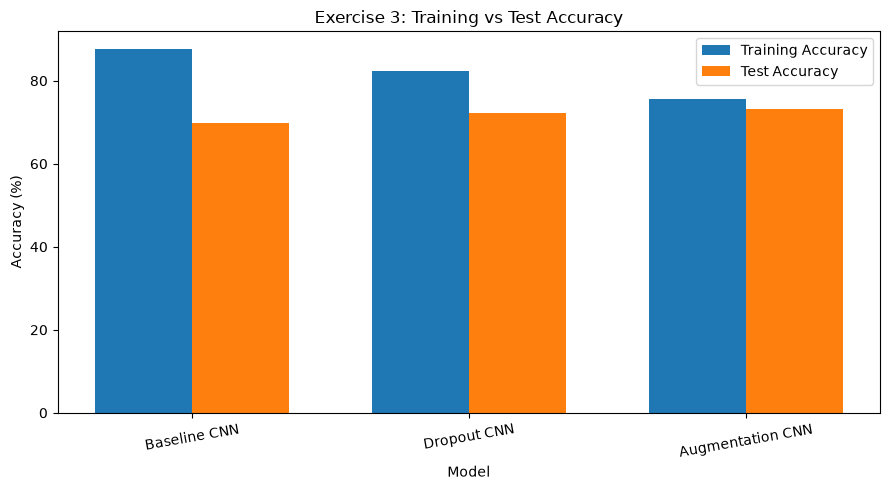

In [16]:
models = ["Baseline CNN", "Dropout CNN", "Augmentation CNN"]

train_accuracies = [
    baseline_results["Training Accuracy"],
    dropout_results["Training Accuracy"],
    augmentation_results["Training Accuracy"]
]

test_accuracies = [
    baseline_results["Test Accuracy"],
    dropout_results["Test Accuracy"],
    augmentation_results["Test Accuracy"]
]

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(x - width/2, train_accuracies, width, label="Training Accuracy")
plt.bar(x + width/2, test_accuracies, width, label="Test Accuracy")

plt.xlabel("Model")
plt.ylabel("Accuracy (%)")
plt.title("Exercise 3: Training vs Test Accuracy")
plt.xticks(x, models, rotation=10)
plt.legend()
plt.tight_layout()

plt.savefig("outputs/exercise3_accuracy_comparison.png")
plt.show()

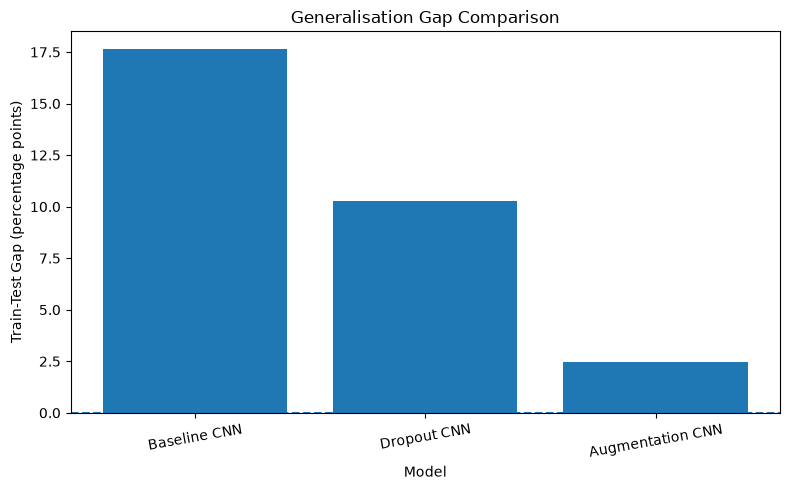

In [17]:
gaps = [
    baseline_results["Train-Test Gap"],
    dropout_results["Train-Test Gap"],
    augmentation_results["Train-Test Gap"]
]

plt.figure(figsize=(8, 5))

plt.bar(models, gaps)

plt.xlabel("Model")
plt.ylabel("Train-Test Gap (percentage points)")
plt.title("Generalisation Gap Comparison")
plt.xticks(rotation=10)
plt.axhline(y=0, linestyle="--")
plt.tight_layout()

plt.savefig("outputs/exercise3_gap_comparison.png")
plt.show()

## Exercise 3: Regularisation and Generalisation

### 1. Baseline CNN

The baseline CNN achieved a training accuracy of **87.52%**, a validation accuracy of **69.80%**, and a test accuracy of **69.90%**. The difference between training and test accuracy was **17.62 percentage points**.

This relatively large gap indicates that the model performed considerably better on the training data than on unseen test data. This suggests that the baseline CNN experienced overfitting. Although it learned the training images effectively, its ability to generalise to unseen images was more limited.

### 2. Dropout CNN

The dropout model achieved a training accuracy of **82.43%**, a validation accuracy of **72.94%**, and a test accuracy of **72.16%**. Its train-test gap decreased to **10.27 percentage points**.

Compared with the baseline, training accuracy decreased by 5.09 percentage points, while test accuracy increased by 2.26 percentage points. The generalisation gap also decreased by 7.35 percentage points.

This suggests that dropout helped reduce overfitting. By randomly disabling 30% of neurons during training, dropout encouraged the network to learn more robust features instead of relying too heavily on particular neurons. As a result, the model performed better on unseen test images.

### 3. Data Augmentation CNN

The data augmentation model achieved a training accuracy of **75.67%**, a validation accuracy of **73.96%**, and a test accuracy of **73.23%**. Its train-test gap was only **2.44 percentage points**.

This model achieved the highest test accuracy and the smallest generalisation gap among the three experiments. Compared with the baseline, test accuracy increased by 3.33 percentage points, while the train-test gap decreased by 15.18 percentage points.

Data augmentation introduced random cropping and horizontal flipping to the training images. This exposed the CNN to slightly different versions of the images during training, helping it learn features that were less dependent on the exact position or orientation of objects. Consequently, the model became better at recognising previously unseen images.

The lower training accuracy does not necessarily indicate worse performance. Instead, it suggests that learning from varied training images made the task more challenging while improving performance on unseen data.

### 4. Comparison of the Three Models

| Model | Training Accuracy | Test Accuracy | Train-Test Gap |
|---|---:|---:|---:|
| Baseline CNN | 87.52% | 69.90% | 17.62 |
| Dropout CNN | 82.43% | 72.16% | 10.27 |
| Augmentation CNN | 75.67% | 73.23% | 2.44 |

The results show that both regularisation techniques improved generalisation compared with the baseline CNN.

Dropout provided a moderate improvement by increasing test accuracy and reducing the difference between training and test performance. However, data augmentation achieved the strongest results, with the highest test accuracy of 73.23% and the smallest train-test gap of 2.44 percentage points.

### 5. Conclusion

Overall, data augmentation was the most effective regularisation technique in this experiment. It improved test accuracy and substantially reduced the generalisation gap compared with the baseline CNN.

Dropout also improved generalisation, although its improvement was smaller than that achieved through data augmentation.

These findings suggest that exposing the CNN to varied training images through random cropping and horizontal flipping was particularly effective for the CIFAR-10 image classification task. Therefore, data augmentation provided the best balance between model performance and generalisation among the three approaches tested.